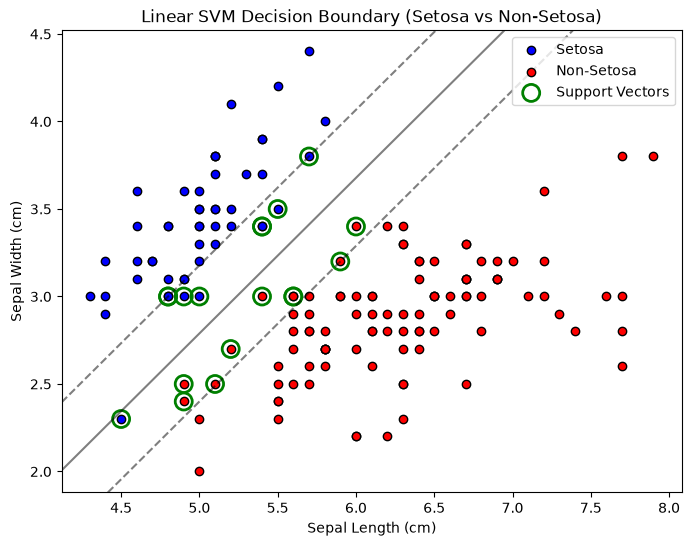

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.svm import SVC

iris = datasets.load_iris()
X = iris.data[:, :2]
y = iris.target


y_binary = np.where(y == 0, 0, 1)

clf = SVC(kernel='linear', C=1.0)
clf.fit(X, y_binary)

plt.figure(figsize=(8, 6))

plt.scatter(X[y_binary == 0][:, 0], X[y_binary == 0][:, 1], color='blue', label='Setosa', edgecolors='k')
plt.scatter(X[y_binary == 1][:, 0], X[y_binary == 1][:, 1], color='red', label='Non-Setosa', edgecolors='k')

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf.decision_function(xy).reshape(XX.shape)

ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=150, 
           linewidth=2, facecolors='none', edgecolors='green', label='Support Vectors')

plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Linear SVM Decision Boundary (Setosa vs Non-Setosa)')
plt.legend()
plt.show()